<a href="https://colab.research.google.com/github/fauziihadiwijaya/Uts-deep-learning-2026/blob/main/classification/Multimodal_Classification_Product_Defects.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 1 — Multimodal Defect Classification (image + press sensor)**

## Summary

1. Tools: PyTorch
2. Methods: CNN dan 1D-CNN
3. Fusion: concat, late, dan xattn
4. Fusion terbaik: concat (F1 0.8528)
5. Modalitas: image-only 0.6666, sensor-only 0.4579, fusion 0.8528
6. Label noise: out-of-fold + confident learning, GCE (0.8595)
7. Domain shift: per-line normalization dan line weights
8. Missing modality: mask channel, missing embedding, modality dropout
9. Training: overfit satu batch, learning curves, 3 seed
10. Final: concat + GCE, ensemble 3 seed + TTA, F1 0.8663


## **0. Setup Lingkungan & Hyperparameter**

Bagian ini menyiapkan pustaka yang dibutuhkan, jalur direktori input/output, random seed, serta konfigurasi hyperparameter dalam dictionary CFG. Terdapat SMOKE sebagai mode uji cepat yang menjalankan keseluruhan alur notebook dengan sedikit sampel selama 1 epoch untuk memverifikasi bahwa tidak ada bug sebelum dijalankan dengan keseluruhan data.

In [1]:
import os, sys, time, math, random, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold
from IPython.display import display

DATA_DIR = Path(os.environ.get('DATA_DIR', '/content/drive/MyDrive/UTS_DL'))
SMOKE    = os.environ.get('SMOKE', '0') == '1'                             # ubah ke true biar aktif

if str(DATA_DIR).startswith('/content/drive') and not Path('/content/drive/MyDrive').exists():
    from google.colab import drive
    drive.mount('/content/drive')

OUT_DIR = Path(os.environ.get('OUT_DIR', DATA_DIR / 'hasil_tugas1')) / ('smoke' if SMOKE else '')
OUT_DIR.mkdir(parents=True, exist_ok=True)

CFG = dict(
    epochs=30, batch=256, lr=2e-3, wd=0.05,      # optimizer AdamW + warmup & cosine annealing
    dim=256, drop=0.2,                           # dimensi fitur representasi & dropout sebelum classifier
    val_frac=0.15, split_seed=0, seeds=[0, 1, 2],
    p_sen=0.15, p_ch=0.10,                       # probabilitas modality dropout
    ls=0.1, gce_q=0.7,                           # hyperparameter label smoothing dan GCE
    oof_folds=3, oof_epochs=12,                  # cross-validation singkat untuk deteksi label mencurigakan
)
if SMOKE:
    CFG.update(epochs=1, oof_epochs=1, oof_folds=2, batch=32)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = dev.type == 'cuda'
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'lines.linewidth': 1.8, 'axes.prop_cycle': mpl.cycler(color=PAL),
                     'axes.titlesize': 10, 'axes.labelsize': 9, 'legend.frameon': False, 'legend.fontsize': 8})

print('python', platform.python_version(), '| torch', torch.__version__, '| numpy', np.__version__,
      '| pandas', pd.__version__, '| sklearn', sklearn.__version__)
print('device:', torch.cuda.get_device_name(0) if dev.type == 'cuda' else 'CPU', '| out:', OUT_DIR)

Mounted at /content/drive
python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
device: Tesla T4 | out: /content/drive/MyDrive/UTS_DL/hasil_tugas1


## 1. Exploration (a)

Tahap awal difokuskan untuk memahami struktur array gambar, rekaman sensor, dan produksi. Pemeriksaan assert untuk memastikan bahwa baris ke-i pada metadata berkorespondensi tepat dengan indeks ke-i pada array data. Karena nilai sensor mentah disimpan dalam format float16 dan nilai NaN pada rekaman yang hilang, data dikonversi ke float32 terlebih dahulu agar stabil secara numerik tanpa menghapus informasi NaN tersebut.

In [2]:
CLASSES = ['normal', 'gores', 'noda', 'retak', 'gelembung', 'las_dingin', 'kontaminasi']
K = len(CLASSES)
CH = ['temperature (C)', 'vibration', 'current (A)']

meta_tr = pd.read_csv(DATA_DIR / 'klasifikasi_train_meta.csv')
meta_te = pd.read_csv(DATA_DIR / 'klasifikasi_test_meta.csv')
ztr, zte = np.load(DATA_DIR / 'klasifikasi_train.npz'), np.load(DATA_DIR / 'klasifikasi_test.npz')
img_tr, sen_tr = ztr['gambar'], ztr['sensor'].astype(np.float32)
img_te, sen_te = zte['gambar'], zte['sensor'].astype(np.float32)
for m, g in [(meta_tr, img_tr), (meta_te, img_te)]:
    assert (m['indeks'].values == np.arange(len(g))).all()
assert set(meta_tr['kelas']) == set(CLASSES)

if SMOKE:   # ambil sebagian kecil sampel
    rng = np.random.default_rng(0)
    keep = np.sort(np.concatenate([rng.choice(ix, min(10, len(ix)), replace=False)
                                   for ix in meta_tr.groupby(['kelas', 'lini']).indices.values()]))
    meta_tr, img_tr, sen_tr = meta_tr.iloc[keep].reset_index(drop=True), img_tr[keep], sen_tr[keep]
    meta_te, img_te, sen_te = meta_te.iloc[:40].reset_index(drop=True), img_te[:40], sen_te[:40]

N = len(meta_tr)
y_all    = meta_tr['kelas'].map({c: i for i, c in enumerate(CLASSES)}).values.astype(np.int64)
line_all = (meta_tr['lini'] == 'B').values.astype(np.int64)        # 0 = lini A, 1 = lini B
line_te  = (meta_te['lini'] == 'B').values.astype(np.int64)
print('train', img_tr.shape, sen_tr.shape, '| test', img_te.shape, sen_te.shape)
meta_tr.head()

train (48000, 64, 64) (48000, 3, 128) | test (16000, 64, 64) (16000, 3, 128)


,indeks,id_unit,lini,shift,id_mesin,batch_material,kelas
0,0,U384670,A,pagi,M05,B135,gores
1,1,U487023,A,malam,M04,B146,gores
2,2,U327240,B,pagi,M09,B003,normal
3,3,U696502,A,siang,M06,B085,noda
4,4,U272751,B,siang,M08,B106,normal


**Class distribution.** Terlihat ketimpangan proporsi yang cukup tajam sekitar separuh dataset latih merupakan unit normal, sedangkan kontaminasi menjadi kelas yang jarang muncul. Mengingat metrik evaluasi akhir adalah macro-F1 yang memberi bobot setara bagi ketujuh kelas, kegagalan memprediksi kelas minoritas dapat menjatuhkan skor akhir secara signifikan.

lini,A,B,total,share,share_in_A,share_in_B
kelas,,,,,,
normal,17862,6026,23888,0.498,0.497,0.501
gores,4231,1392,5623,0.117,0.118,0.116
noda,3568,1205,4773,0.099,0.099,0.100
retak,2699,907,3606,0.075,0.075,0.075
gelembung,2577,853,3430,0.071,0.072,0.071
las_dingin,3250,1073,4323,0.090,0.090,0.089
kontaminasi,1777,580,2357,0.049,0.049,0.048


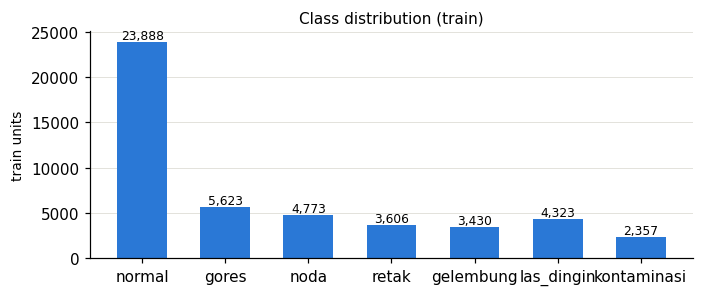

In [3]:
cnt = pd.crosstab(meta_tr['kelas'], meta_tr['lini']).reindex(CLASSES)
cnt['total'] = cnt.sum(axis=1)
cnt['share'] = (cnt['total'] / N).round(3)
cnt['share_in_A'] = (cnt['A'] / cnt['A'].sum()).round(3)
cnt['share_in_B'] = (cnt['B'] / cnt['B'].sum()).round(3)
display(cnt)

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.bar(CLASSES, cnt['total'], color=PAL[0], width=0.6)
for i, v in enumerate(cnt['total']):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
ax.set_ylabel('train units'); ax.set_title('Class distribution (train)'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

**Train vs test metadata.** Perbandingan metadata mengungkap adanya pergeseran distribusi pada atribut lini. Data latih didominasi oleh lini A, sedangkan data uji justru didominasi oleh lini B. Mesin M01-M06 beroperasi hanya di lini A dan M07-M12 di lini B, sehingga pergeseran pada id_mesin merupakan cerminan langsung dari pergeseran lini produksi. Sementara itu, distribusi shift kerja terpantau seimbang.

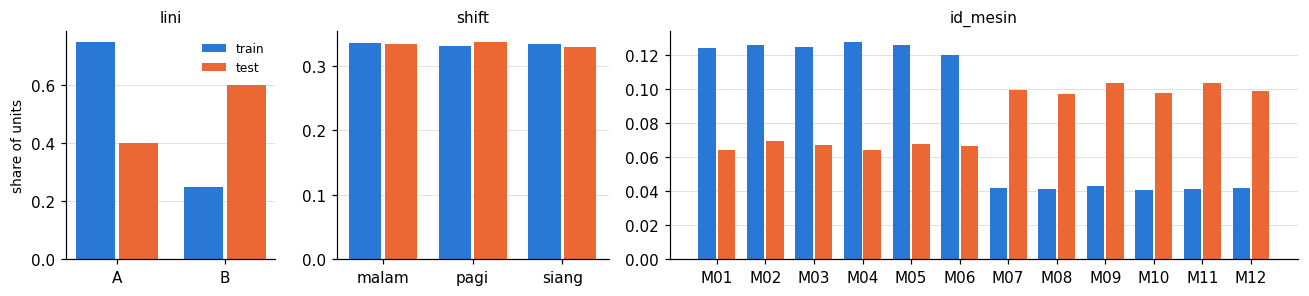

machines per line (train):


id_mesin,M01,M02,M03,M04,M05,M06,M07,M08,M09,M10,M11,M12
lini,,,,,,,,,,,,
A,5976,6058,5986,6134,6040,5770,0,0,0,0,0,0
B,0,0,0,0,0,0,2016,1981,2083,1943,1994,2019


line share  train: [0.749 0.251]  test: [0.4 0.6]


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), gridspec_kw={'width_ratios': [1, 1.3, 3]})
for ax, col in zip(axes, ['lini', 'shift', 'id_mesin']):
    p = pd.DataFrame({'train': meta_tr[col].value_counts(normalize=True),
                      'test':  meta_te[col].value_counts(normalize=True)}).sort_index().fillna(0)
    x = np.arange(len(p))
    ax.bar(x - 0.2, p['train'], 0.36, label='train', color=PAL[0])
    ax.bar(x + 0.2, p['test'],  0.36, label='test',  color=PAL[1])
    ax.set_xticks(x); ax.set_xticklabels(p.index); ax.set_title(col); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('share of units'); axes[0].legend()
plt.tight_layout(); plt.show()

print('machines per line (train):')
display(pd.crosstab(meta_tr['lini'], meta_tr['id_mesin']))
P_LINE_TEST = np.bincount(line_te, minlength=2) / len(line_te)      # disimpan untuk mereplikasi proporsi lini uji
print('line share  train:', np.round(np.bincount(line_all, minlength=2) / N, 3), ' test:', np.round(P_LINE_TEST, 3))

**Images per class and line.** Visualisasi 4 sampel acak per kelas dari lini A dan lini B terdapat perbedaan dan tampilan:
1. Perbedaan tekstur latar, Permukaan unit dari lini A memiliki pola bercak, sedangkan lini B tampak lebih gelap dengan guratan garis searah.
2. Visibilitas cacat, Cacat seperti gores, noda, retak, gelembung, dan kontaminasi meninggalkan jejak visual meski sebagian samar samar. Sebaliknya, las_dingin nyaris identik dengan permukaan normal, menandakan kelas ini tidak dapat diandalkan hanya dari gambar kamera.

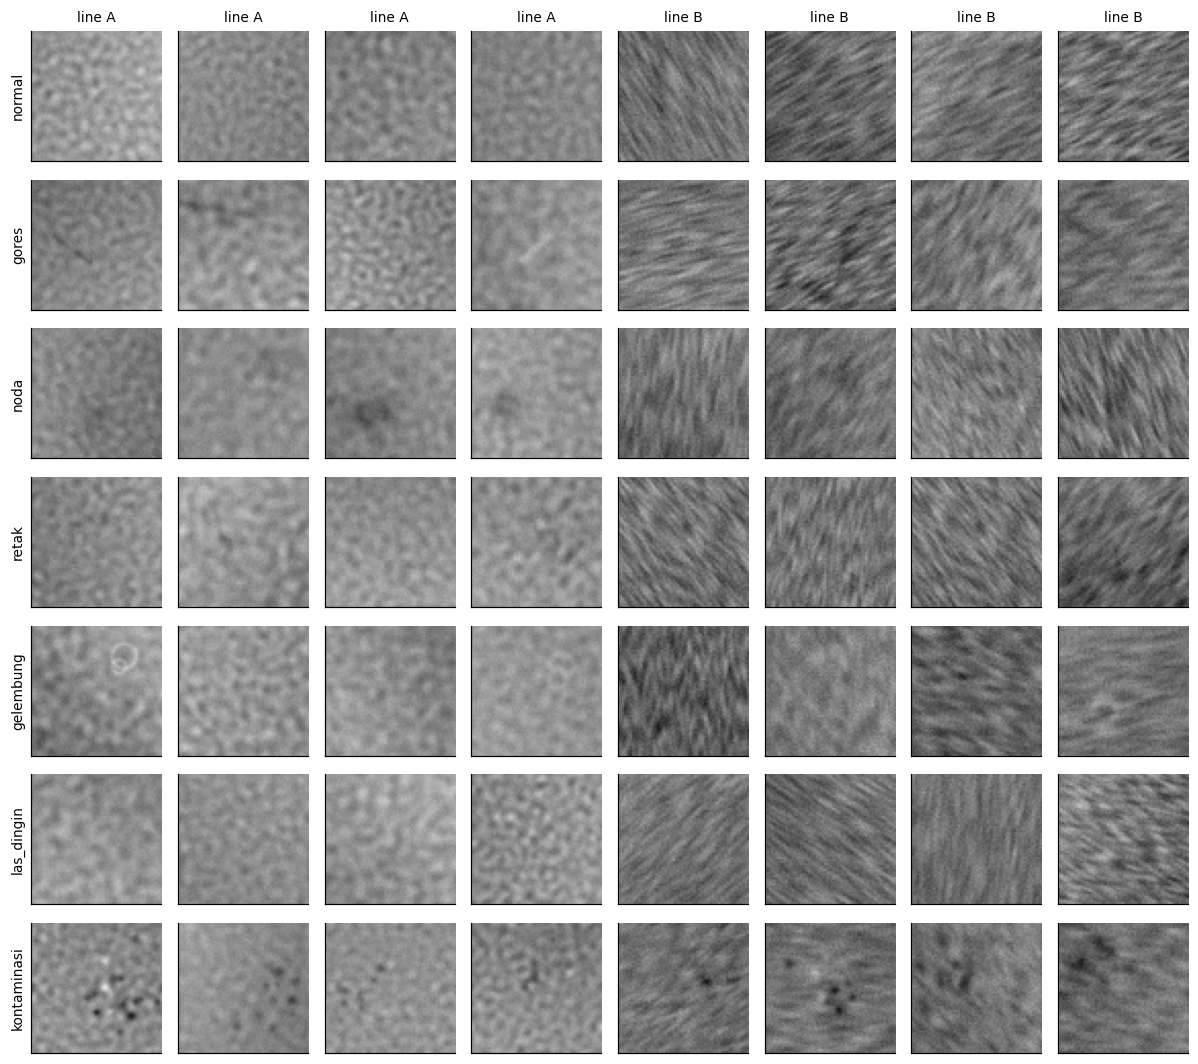

In [5]:
rng = np.random.default_rng(1)
fig, axes = plt.subplots(K, 8, figsize=(11, 9.8))
for i, c in enumerate(CLASSES):
    for j in range(8):
        pool = np.where((y_all == i) & (line_all == (j >= 4)))[0]
        ax = axes[i, j]; ax.imshow(img_tr[rng.choice(pool)], cmap='gray', vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if j == 0: ax.set_ylabel(c, fontsize=9)
        if i == 0: ax.set_title('line A' if j < 4 else 'line B', fontsize=9)
plt.tight_layout(); plt.show()

**Sensor signals per class.** Karena sinyal individual mengandung noise yang tinggi, kurva di bawah memplot rata-rata tiap channel berdasarkan kelas. Tiga kelas menunjukkan tanda khas pada sensor gelembung memicu penurunan kurva suhu, las_dingin menunjukan aliran arus listrik yang lebih rendah, dan retak menghasilkan amplitudo getaran yang jauh lebih besar dibanding kelas lain. Sementara itu, cacat permukaan murni seperti gores dan noda memiliki pola sinyal yang mirip dengan sinyal normal.

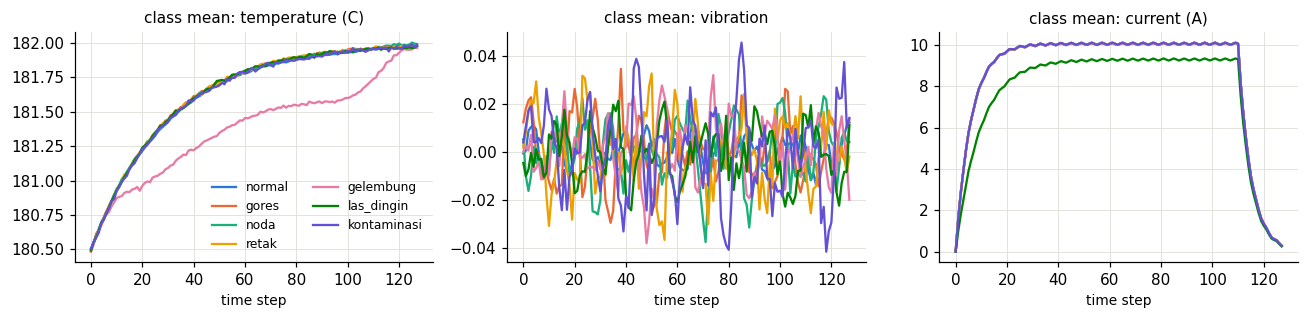

,peak-to-peak temperature (C),peak-to-peak vibration,peak-to-peak current (A)
normal,2.95,3.26,10.25
gores,2.93,3.26,10.25
noda,2.97,3.26,10.26
retak,2.93,3.68,10.26
gelembung,3.96,3.25,10.25
las_dingin,2.93,3.26,9.49
kontaminasi,2.93,3.25,10.26


In [6]:
complete_tr = ~np.isnan(sen_tr).any((1, 2))          # unit dengan ketiga sensor lengkap
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ch, ax in enumerate(axes):
    for i, c in enumerate(CLASSES):
        ax.plot(sen_tr[(y_all == i) & complete_tr, ch].mean(0), label=c, color=PAL[i], lw=1.5)
    ax.set_title(f'class mean: {CH[ch]}'); ax.set_xlabel('time step')
axes[0].legend(ncol=2)
plt.tight_layout(); plt.show()

p2p = pd.DataFrame([(sen_tr[(y_all == i) & complete_tr].max(2) - sen_tr[(y_all == i) & complete_tr].min(2)).mean(0)
                    for i in range(K)], index=CLASSES, columns=[f'peak-to-peak {c}' for c in CH]).round(2)
display(p2p)

**Missing sensor recordings (NaN).** Pemeriksaan assert mengonfirmasi bahwa nilai NaN selalu mencakup satu channel penuh, tidak pernah terputus di tengah rekaman. Sekitar 5% unit kehilangan seluruh data sensor dan 3% lainnya kehilangan satu chanel. Karena tingkat kehilangan ini seragam di seluruh kelas, lini produksi, maupun antara train dan test, absennya sensor bersifat acak dan bukan indikator kelas cacat tertentu namun arsitektur model harus dirancang agar tetap akurat saat sensor tidak tersedia.

In [7]:
def missing_table(sen):
    ch_missing = np.isnan(sen).all(2)                               # seluruh channel bernilai NaN
    assert (np.isnan(sen).any(2) == ch_missing).all()               # memastikan tidak ada NaN
    return ch_missing, {'no sensor at all': ch_missing.all(1).mean(), 'one channel missing': (ch_missing.sum(1) == 1).mean(),
                        'two channels missing': (ch_missing.sum(1) == 2).mean(),
                        **{f'missing {c}': ch_missing[:, i].mean() for i, c in enumerate(CH)}}
chm_tr, row_tr = missing_table(sen_tr)
chm_te, row_te = missing_table(sen_te)
display(pd.DataFrame({'train': row_tr, 'test': row_te}).round(4))

none_tr = chm_tr.all(1)                                             # tanpa sensor
has_tr  = ~none_tr                                                  # ada satu channel terekam
display(pd.DataFrame({'no sensor, by class': pd.Series(none_tr).groupby(meta_tr['kelas'].values).mean().reindex(CLASSES),
                      }).round(4).T)
print('no sensor, by line (train):', pd.Series(none_tr).groupby(meta_tr['lini'].values).mean().round(4).to_dict())

,train,test
no sensor at all,0.0490,0.0508
one channel missing,0.0315,0.0303
two channels missing,0.0000,0.0000
missing temperature (C),0.0595,0.0608
missing vibration,0.0593,0.0616
missing current (A),0.0596,0.0604


,normal,gores,noda,retak,gelembung,las_dingin,kontaminasi
"no sensor, by class",0.0476,0.0518,0.0517,0.0555,0.051,0.047,0.0416


no sensor, by line (train): {'A': 0.0486, 'B': 0.0502}


**How the two lines differ.** Distribusi intensitas piksel dan suhu rata-rata memperliatkan karakteristik domain shift antara kedua lini dimana citra pada lini B memiliki rata-rata kecerahan lebih rendah dengan simpangan baku, sementara pembacaan suhu mesin press pada lini B bergeser lebih tinggi dibanding lini A. channel getaran dan arus listrik tetap konsisten di kedua lini. Temuan ini menjadi dasar perancangan normalisasi per lini.

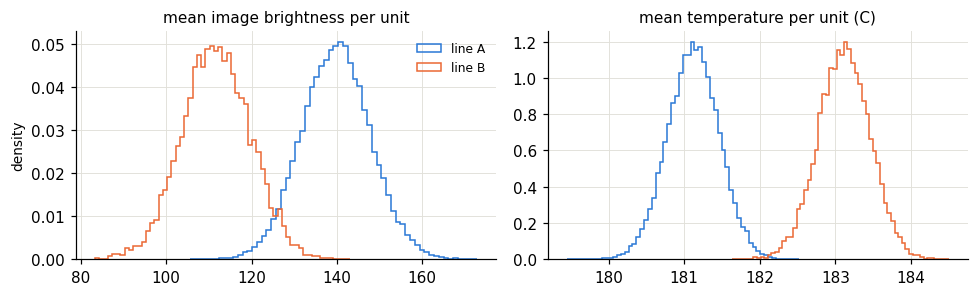

,split,line,n,img_mean,img_std,mean temperature (C),mean vibration,mean current (A)
0,train,A,35964,139.79,15.25,181.119995,0.0,8.47
1,train,B,12036,111.73,19.08,183.119995,0.0,8.42
2,test,A,6393,139.89,15.21,181.119995,-0.0,8.48
3,test,B,9607,111.65,19.08,183.130005,0.0,8.41


In [8]:
bright = img_tr.reshape(N, -1).mean(1)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')                      # mengabaikan peringatan NaN pada unit yang tidak ada channel suhu
    temp = np.nanmean(sen_tr[:, 0], axis=1)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
for l, name in enumerate(['line A', 'line B']):
    axes[0].hist(bright[line_all == l], bins=60, histtype='step', density=True, label=name, color=PAL[l], lw=1.8)
    axes[1].hist(temp[(line_all == l) & ~np.isnan(temp)], bins=60, histtype='step', density=True, label=name, color=PAL[l], lw=1.8)
axes[0].set_title('mean image brightness per unit'); axes[1].set_title('mean temperature per unit (C)')
axes[0].set_ylabel('density'); axes[0].legend()
plt.tight_layout(); plt.show()

rows = []
for name, im, se, ln in [('train', img_tr, sen_tr, line_all), ('test', img_te, sen_te, line_te)]:
    for l in (0, 1):
        m = ln == l
        rows.append(dict(split=name, line='AB'[l], n=int(m.sum()), img_mean=im[m].mean(), img_std=im[m].std(),
                         **{f'mean {c}': v for c, v in zip(CH, np.nanmean(se[m], axis=(0, 2)))}))
display(pd.DataFrame(rows).round(2))

## 2. Split, normalization, batching

**Split.** Pembagian data latih (85%) dan validasi (15%) dilakukan secara proporsional berdasarkan kombinasi kelas dan lini agar komposisi kelas minoritas di tiap lini produksi tetap seimbang pada kedua subset.

**Normalization.** Seluruh rata-rata dan standar deviasi dihitung murni dari subset latih untuk mencegah kebocoran data. Disiapkan dua mode normalisasi, yakni global (satu parameter statistik untuk seluruh data) dan line (statistik terpisah untuk lini A dan lini B). Karena informasi kolom lini tersedia pada data uji, normalisasi per lini sah digunakan saat inferensi.

**Validation Matrix.** Data validasi mewarisi komposisi data latih (75% lini A), padahal data uji didominasi lini B (60%). Oleh karena itu, selain mencatat macro-F1 standar, dihitung pula f1_mix, yakni macro-F1 dengan bobot sampel sebesar P_test(lini) / P_val(lini) sebagai estimator yang lebih akurat terhadap performa pada hidden test set untuk pemilihan model terbaik.

In [9]:
idx = np.arange(N)
tr_idx, va_idx = train_test_split(idx, test_size=CFG['val_frac'], stratify=y_all * 2 + line_all,
                                  random_state=CFG['split_seed'])
tr_idx, va_idx = np.sort(tr_idx), np.sort(va_idx)
print(f'train {len(tr_idx):,} | val {len(va_idx):,}')

def norm_stats(sel):
    """Menghitung mean/std citra dan sensor per kanal untuk tiap lini (baris 0 = lini A, baris 1 = lini B)."""
    out = {}
    for mode in ('global', 'line'):
        mi, si, ms, ss = [], [], [], []
        for l in (0, 1):
            s = sel if mode == 'global' else sel[line_all[sel] == l]
            h = np.bincount(img_tr[s].ravel(), minlength=256).astype(np.float64); v = np.arange(256)
            mu = (h * v).sum() / h.sum()
            mi.append(mu); si.append(np.sqrt((h * (v - mu) ** 2).sum() / h.sum()))
            ms.append(np.nanmean(sen_tr[s], axis=(0, 2))); ss.append(np.nanstd(sen_tr[s], axis=(0, 2)))
        out[mode] = tuple(torch.tensor(np.array(a), dtype=torch.float32, device=dev) for a in (mi, si, ms, ss))
    return out
STATS = norm_stats(tr_idx)
for mode in STATS:
    print(mode, '| img mean', STATS[mode][0].cpu().numpy().round(1), '| temp mean', STATS[mode][2][:, 0].cpu().numpy().round(2))

train 40,800 | val 7,200
global | img mean [132.7 132.7] | temp mean [181.62 181.62]
line | img mean [139.8 111.7] | temp mean [181.12 183.12]


**Batches straight from GPU memory.** Ukuran keseluruhan dataset sekitar 350 MB, sehingga seluruh tensor dipindahkan sekaligus ke VRAM GPU. Penyusunan mini-batch melalui pengindeksan tensor secara langsung jauh lebih cepat dibandingkan PyTorch DataLoader standar yang sering terhambat CPU pada lingkungan Colab.

Fungsi make_batch menjalankan empat transformasi utama:
- **Standardisasi:** Menerapkan statistik global atau line pada citra dan sinyal sensor.
- **Encoding Missingness:** Nilai NaN pada rekaman sensor diisi dengan 0.0 dan dilengkapi 3 channel penanda biner (1 = terekam, 0 = hilang) agar model tetap tahu mana sinyal yang asli dan mana yang kosong, menghasilkan tensor masukan berdimensi (B, 6, 128).
- **Data Augmentation (khusus fase latih):** Pencerminan horizontal/vertikal serta pemutaran sumbu secara acak pada citra karena bentuk cacat permukaan tidak bergantung pada arah disertai penambahan noise Gaussian ringan pada sinyal sensor.
- **Modality Dropout (khusus fase latih):** Menonaktifkan seluruh sinyal sensor dengan probabilitas p_sen maupun masing-masing kanal secara independen dengan probabilitas p_ch, melatih model agar tetap tangguh menghadapi rekaman yang hilang.

In [10]:
TR = dict(img=torch.from_numpy(img_tr).to(dev), sen=torch.from_numpy(sen_tr).to(dev),
          line=torch.from_numpy(line_all).to(dev), y=torch.from_numpy(y_all).to(dev))
TE = dict(img=torch.from_numpy(img_te).to(dev), sen=torch.from_numpy(sen_te).to(dev),
          line=torch.from_numpy(line_te).to(dev))

def make_batch(D, b, norm='global', train=False, p_sen=0.0, p_ch=0.0, sensor_off=False, flip=0):
    mi, si, ms, ss = STATS[norm]
    ln = D['line'][b]
    x = (D['img'][b].float() - mi[ln][:, None, None]) / si[ln][:, None, None]            # (B, 64, 64)
    s = D['sen'][b]
    m = ~torch.isnan(s)                                                                  # (B, 3, 128) recorded?
    s = (torch.nan_to_num(s) - ms[ln][:, :, None]) / ss[ln][:, :, None]
    if sensor_off:
        m = torch.zeros_like(m)
    if flip & 1: x = x.flip(2)                                                           # flip untuk TTA
    if flip & 2: x = x.flip(1)
    if train:
        B = len(b)
        x = torch.where(torch.rand(B, 1, 1, device=dev) < 0.5, x.flip(2), x)
        x = torch.where(torch.rand(B, 1, 1, device=dev) < 0.5, x.flip(1), x)
        if torch.rand(()) < 0.5: x = x.transpose(1, 2)
        s = s + 0.05 * torch.randn_like(s)
        m = m & (torch.rand(B, 1, 1, device=dev) >= p_sen) & (torch.rand(B, 3, 1, device=dev) >= p_ch)
    m = m.float()
    xi = x[:, None].contiguous(memory_format=torch.channels_last)
    return xi, torch.cat([s * m, m], 1)                                                  # gambar (B,1,64,64), sensor (B,6,128)

xi, xs = make_batch(TR, torch.arange(4, device=dev), train=True, p_sen=0.5)
print(xi.shape, xs.shape)

torch.Size([4, 1, 64, 64]) torch.Size([4, 6, 128])


## 3. Architecture (b)

**Image encoder**: Menggunakan arsitektur CNN bergaya ResNet ringan. Konvolusi pertama mempertahankan resolusi penuh 64x64 agar detail cacat tipis seperti gores dan retak yang lebarnya hanya 1-2 piksel tidak hilang akibat downsampling terlalu dini, dilanjutkan dengan tiga blok residual yang masing-masing memangkas resolusi menjadi setengahnya (64 → 32 → 16 → 8). Hasil akhirnya adalah peta fitur berukuran 8x8 dengan 256 channel, yang kemudian diratakan menjadi 64 token spasial.

**Signal encoder**: Menggunakan struktur 1D serupa dengan ukuran kernel lebih lebar (k=7 dan k=5) untuk menangkap pola temporal gelombang suhu, getaran, dan arus. Keluarannya direduksi menjadi 16 token temporal berdimensi 256.

**Missing sensor**: jika tidak ada saluran yang direkam, token sensor diganti dengan satu vektor hilang yang dipelajari. Model kemudian tahu sensor itu tidak ada, alih-alih membaca nol sebagai sinyal nyata.

**Fusion strategies** (mode):
- concat (feature-level fusion): meringkas keluaran masing-masing encoder menggunakan average pooling, menyatukan kedua vektor representasinya, lalu meneruskannya ke MLP ringan. Dengan cara ini, klasifier dapat memadukan petunjuk dari citra dan sensor secara bersamaan.
- late (decision-level fusion): Masing-masing modalitas memiliki kepala klasifikasi linear terpisah dan prediksi akhir diperoleh dengan menjumlahkan logit keduanya. Pendekatan ini memodelkan voting independen tanpa interaksi fitur lintas modalitas.
- xattn (cross-attention): token gambar memperhatikan token sensor dan sebaliknya, lalu digabungkan dan diklasifikasikan. Model bisa menghubungkan di mana dalam gambar dengan kapan dalam sinyal.

image and sensor are the single-modality models.

In [11]:
class Res(nn.Module):
    """Blok residual: dua lapisan conv-BN ditambah koneksi skip. nd=2 untuk gambar, nd=1 untuk sinyal."""
    def __init__(self, nd, cin, cout, stride, k=3):
        super().__init__()
        Conv, BN = (nn.Conv2d, nn.BatchNorm2d) if nd == 2 else (nn.Conv1d, nn.BatchNorm1d)
        self.c1, self.b1 = Conv(cin, cout, k, stride, k // 2, bias=False), BN(cout)
        self.c2, self.b2 = Conv(cout, cout, k, 1, k // 2, bias=False), BN(cout)
        self.skip = nn.Sequential(Conv(cin, cout, 1, stride, bias=False), BN(cout))
    def forward(self, x):
        h = F.relu(self.b1(self.c1(x)))
        return F.relu(self.b2(self.c2(h)) + self.skip(x))

class ImageEncoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, 1, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
                                 Res(2, 32, 64, 2), Res(2, 64, 128, 2), Res(2, 128, dim, 2))
    def forward(self, x):                                   # (B,1,64,64) -> (B,64,dim)
        return self.net(x).flatten(2).transpose(1, 2)

class SensorEncoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(6, 64, 7, 1, 3, bias=False), nn.BatchNorm1d(64), nn.ReLU(),
                                 Res(1, 64, 96, 2, k=5), Res(1, 96, 160, 2, k=5), Res(1, 160, dim, 2, k=5))
    def forward(self, x):                                   # (B,6,128) -> (B,16,dim)
        return self.net(x).transpose(1, 2)

class DefectNet(nn.Module):
    def __init__(self, mode, dim=256, drop=0.2):
        super().__init__()
        assert mode in ('image', 'sensor', 'concat', 'late', 'xattn')
        self.mode = mode
        lin = lambda: nn.Sequential(nn.Dropout(drop), nn.Linear(dim, K))
        mlp = lambda: nn.Sequential(nn.Linear(2 * dim, dim), nn.ReLU(), nn.Dropout(drop), nn.Linear(dim, K))
        if mode != 'sensor':
            self.img = ImageEncoder(dim)
        if mode != 'image':
            self.sen = SensorEncoder(dim)
            self.missing = nn.Parameter(torch.zeros(1, 1, dim))             # embedding khusus saat sensor tidak ada
        if mode in ('image', 'sensor'): self.head = lin()
        if mode == 'concat':            self.head = mlp()
        if mode == 'late':              self.head_i, self.head_s = lin(), lin()
        if mode == 'xattn':
            self.pos_i = nn.Parameter(torch.randn(1, 64, dim) * 0.02)        # positional embedding spasial
            self.pos_s = nn.Parameter(torch.randn(1, 16, dim) * 0.02)        # positional embedding temporal
            self.i2s = nn.MultiheadAttention(dim, 4, dropout=0.1, batch_first=True)   # query gambar, key/value sensor
            self.s2i = nn.MultiheadAttention(dim, 4, dropout=0.1, batch_first=True)   # query sensor, key/value gambar
            self.n_i, self.n_s = nn.LayerNorm(dim), nn.LayerNorm(dim)
            self.head = mlp()

    def sensor_tokens(self, xs):
        t = self.sen(xs)
        has = xs[:, 3:].amax(dim=(1, 2)) > 0                                 # cek apakah ada channel sensor yang terekam
        return torch.where(has[:, None, None], t, self.missing.to(t.dtype).expand_as(t))

    def forward(self, xi, xs):
        if self.mode == 'image':
            return self.head(self.img(xi).mean(1))
        ts = self.sensor_tokens(xs)
        if self.mode == 'sensor':
            return self.head(ts.mean(1))
        ti = self.img(xi)
        if self.mode == 'concat':
            return self.head(torch.cat([ti.mean(1), ts.mean(1)], 1))
        if self.mode == 'late':
            return self.head_i(ti.mean(1)) + self.head_s(ts.mean(1))
        ti, ts = ti + self.pos_i, ts + self.pos_s
        ai = self.i2s(ti, ts, ts, need_weights=False)[0]
        a_s = self.s2i(ts, ti, ti, need_weights=False)[0]
        ti, ts = self.n_i(ti + ai), self.n_s(ts + a_s)
        return self.head(torch.cat([ti.mean(1), ts.mean(1)], 1))

for mode in ('image', 'sensor', 'concat', 'late', 'xattn'):
    net = DefectNet(mode, CFG['dim']).to(dev)
    with torch.no_grad():
        out = net.eval()(xi, xs)
    print(f'{mode:7s} params {sum(p.numel() for p in net.parameters()) / 1e6:.2f}M  output {tuple(out.shape)}')

image   params 1.21M  output (4, 7)
sensor  params 0.88M  output (4, 7)
concat  params 2.22M  output (4, 7)
late    params 2.09M  output (4, 7)
xattn   params 2.77M  output (4, 7)


### Training and evaluation helpers

- fit: melatih satu model menggunakan optimizer AdamW, linear warmup pada 5% langkah awal yang dilanjutkan dengan cosine decay, serta mixed precision. Evaluasi dilaporkan pada epoch terakhir. Seluruh hasil mulai dari riwayat pelatihan, probabilitas validasi, hingga bobot model otomatis disimpan dan akan langsung dimuat kembali jika berkasnya sudah ada.
- Class imbalance: Fungsi loss memberi bobot 1/sqrt(frequency) pada setiap kelas sebagai dorongan moderat bagi kelas yang jarang muncul, selaras dengan metrik macro-F1..
- loss: Mendukung cross-entropy, label smoothing, dan generalized cross-entropy, dengan dua opsi terakhir difokuskan untuk eksperimen.
- line_w=True Memboboti setiap sampel sebesar P_test(line) / P_train(line) untuk menyesuaikan proporsi lini produksi saat pelatihan.
- score Menghitung macro-F1 secara keseluruhan, skor terpisah untuk tiap lini, serta f1_mix sebagai estimasi performa pada komposisi data uji.

Pada catatan riwayat pelatihan, baik train_loss maupun val_loss sama-sama dihitung menggunakan cross-entropy standar agar kedua kurvanya sebanding. Nilai loss latih diukur saat augmentasi dan dropout aktif, sehingga wajar jika posisinya berada di atas loss validasi pada awal-awal epoch.

In [12]:
def loss_fn(logits, y, kind, w):
    logits = logits.float()
    if kind == 'gce':                                           # (1 - p_y^q) / q : interpolasi antara CE (q->0) dan MAE (q=1)
        p = F.softmax(logits, 1).gather(1, y[:, None]).squeeze(1).clamp_min(1e-6)
        l = (1 - p.pow(CFG['gce_q'])) / CFG['gce_q']
    else:
        l = F.cross_entropy(logits, y, reduction='none', label_smoothing=CFG['ls'] if kind == 'ls' else 0.0)
    return (l * w).sum() / w.sum()

@torch.no_grad()
def predict(model, D, idx, norm='global', sensor_off=False, tta=False):
    """Menghitung probabilitas kelas untuk indeks `idx`. Jika tta=True, merata-ratakan prediksi dari 4 kombinasi flip."""
    model.eval()
    idx = torch.as_tensor(idx, device=dev); flips = range(4) if tta else [0]; out = []
    for i in range(0, len(idx), 1024):
        p = 0
        for f in flips:
            xi, xs = make_batch(D, idx[i:i + 1024], norm, sensor_off=sensor_off, flip=f)
            with torch.autocast(dev.type, enabled=AMP):
                p = p + F.softmax(model(xi, xs).float(), 1)
        out.append(p / len(flips))
    return torch.cat(out).cpu().numpy()

def macro_f1(y, pred, w=None):
    return f1_score(y, pred, labels=np.arange(K), average='macro', zero_division=0, sample_weight=w) if len(y) else np.nan

def score(prob, idx):
    """Menghitung macro-F1 keseluruhan, per lini, dan f1_mix (terbobot sesuai proporsi lini data uji)."""
    y, pred, ln = y_all[idx], prob.argmax(1), line_all[idx]
    w = (P_LINE_TEST / np.maximum(np.bincount(ln, minlength=2) / len(ln), 1e-9))[ln]
    return dict(f1=macro_f1(y, pred), f1_A=macro_f1(y[ln == 0], pred[ln == 0]), f1_B=macro_f1(y[ln == 1], pred[ln == 1]),
                f1_mix=macro_f1(y, pred, w), acc=float((y == pred).mean()))

def per_class_f1(prob, idx):
    return f1_score(y_all[idx], prob.argmax(1), labels=np.arange(K), average=None, zero_division=0)

RUNS = {}

def fit(name, mode, tr, va, seed=0, epochs=None, loss='ce', norm='global', line_w=False, p_sen=None, p_ch=None, verbose=True):
    epochs = epochs or CFG['epochs']
    p_sen = CFG['p_sen'] if p_sen is None else p_sen
    p_ch  = CFG['p_ch'] if p_ch is None else p_ch
    path = OUT_DIR / f'{name}_e{epochs}.pt'
    if path.exists():
        R = torch.load(path, map_location='cpu', weights_only=False)
        print(f'[{name}] loaded from disk | val macro-F1 {score(R["val_prob"], R["va"])["f1"]:.4f}')
        RUNS[name] = R
        return R

    set_seed(seed)
    model = DefectNet(mode, CFG['dim'], CFG['drop']).to(dev).to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['wd'])
    bs = CFG['batch']; steps = max(1, len(tr) // bs); total = epochs * steps; warm = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda t: (t + 1) / warm if t < warm else 0.5 * (1 + math.cos(math.pi * (t - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler(dev.type, enabled=AMP)

    freq = np.bincount(y_all[tr], minlength=K) / len(tr)
    w_cls = 1 / np.sqrt(np.maximum(freq, 1e-9)); w_cls = torch.tensor(w_cls / (w_cls * freq).sum(), dtype=torch.float32, device=dev)
    p_line = np.bincount(line_all[tr], minlength=2) / len(tr)
    w_line = torch.tensor(P_LINE_TEST / p_line if line_w else np.ones(2), dtype=torch.float32, device=dev)

    tr_t = torch.as_tensor(tr, device=dev); g = torch.Generator().manual_seed(seed); hist = []; t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        perm = tr_t[torch.randperm(len(tr_t), generator=g).to(dev)]
        ce_sum = torch.zeros((), device=dev); preds, ys = [], []
        for i in range(steps):
            b = perm[i * bs:(i + 1) * bs]; yb = TR['y'][b]
            xi, xs = make_batch(TR, b, norm, train=True, p_sen=p_sen, p_ch=p_ch)
            with torch.autocast(dev.type, enabled=AMP):
                out = model(xi, xs)
            l = loss_fn(out, yb, loss, w_cls[yb] * w_line[TR['line'][b]])
            opt.zero_grad(set_to_none=True)
            scaler.scale(l).backward(); scaler.step(opt); scaler.update(); sched.step()
            ce_sum += F.cross_entropy(out.detach().float(), yb); preds.append(out.detach().argmax(1)); ys.append(yb)
        pv = predict(model, TR, va, norm)
        hist.append(dict(epoch=ep, train_loss=ce_sum.item() / steps,
                         train_f1=macro_f1(torch.cat(ys).cpu().numpy(), torch.cat(preds).cpu().numpy()),
                         val_loss=float(-np.log(pv[np.arange(len(va)), y_all[va]] + 1e-9).mean()),
                         val_f1=macro_f1(y_all[va], pv.argmax(1))))
        if verbose and (ep % 5 == 0 or ep in (1, epochs)):
            h = hist[-1]
            print(f'[{name}] ep {ep:2d}/{epochs}  train loss {h["train_loss"]:.3f} f1 {h["train_f1"]:.3f} | '
                  f'val loss {h["val_loss"]:.3f} f1 {h["val_f1"]:.3f} | {time.time() - t0:.0f}s')

    R = dict(name=name, mode=mode, seed=seed, epochs=epochs, loss=loss, norm=norm, line_w=line_w, p_sen=p_sen, p_ch=p_ch,
             hist=hist, va=np.asarray(va), val_prob=pv, secs=time.time() - t0,
             state={k: v.cpu() for k, v in model.state_dict().items()})
    torch.save(R, path)
    RUNS[name] = R
    return R

def load_model(R):
    model = DefectNet(R['mode'], CFG['dim'], CFG['drop'])
    model.load_state_dict(R['state'])
    return model.to(dev).to(memory_format=torch.channels_last).eval()

def table(names, labels=None):
    rows = [dict(run=(labels or names)[i], **score(RUNS[n]['val_prob'], RUNS[n]['va']), minutes=RUNS[n]['secs'] / 60)
            for i, n in enumerate(names)]
    return pd.DataFrame(rows).set_index('run').round(4)

def heat(ax, M, rows, cols, title='', vmax=1.0, fmt='.2f'):
    """Annotated heatmap, one hue, light = low and dark = high."""
    M = np.asarray(M, dtype=float)
    ax.imshow(M, cmap='Blues', vmin=0, vmax=vmax, aspect='auto'); ax.grid(False)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=30, ha='right'); ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M[i, j]):
                ax.text(j, i, format(M[i, j], fmt), ha='center', va='center', fontsize=8,
                        color='white' if M[i, j] > 0.6 * vmax else '#0b0b0b')
    ax.set_title(title)

def plot_curves(names, labels=None, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for i, n in enumerate(names):
        h = pd.DataFrame(RUNS[n]['hist']); lab = (labels or names)[i]
        axes[0].plot(h['epoch'], h['val_loss'], color=PAL[i], label=lab, marker='o', ms=2.5)
        axes[1].plot(h['epoch'], h['val_f1'], color=PAL[i], label=lab, marker='o', ms=2.5)
    axes[0].set_title('validation loss (cross-entropy)'); axes[1].set_title('validation macro-F1')
    for ax in axes: ax.set_xlabel('epoch')
    axes[1].legend(); fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

## 4. Sanity check: overfit one batch (g)

Sebelum mengalokasikan waktu komputasi GPU untuk pelatihan penuh, alur pemrosesan data, arsitektur, dan backpropagation diverifikasi terlebih dahulu melalui pengujian overfit pada satu batch kecil berisi 64 unit latih tanpa augmentasi maupun dropout. Dua kriteria kelulusan yang diperiksa:
1. Nilai loss pada iterasi pertama berada di nilai ln(7) = 1.946 tebakan seragam pada 7 kelas dari bobot terinisialisasi acak.
2. Dalam 200 langkah optimasi, loss turun mendekati nol dan akurasi mencapai 100%, membuktikan tidak ada bug pada penyelarasan label maupun aliran gradien.

first loss 1.990 (ln 7 = 1.946) | final loss 0.0000 | final accuracy 100.00%


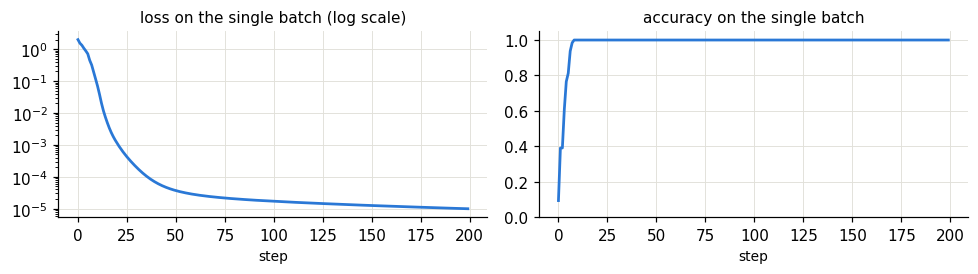

In [13]:
set_seed(0)
b = torch.as_tensor(tr_idx[:64], device=dev)
xi, xs = make_batch(TR, b); yb = TR['y'][b]
net = DefectNet('concat', CFG['dim'], drop=0.0).to(dev)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
log = []
for step in range(5 if SMOKE else 200):
    net.train()
    out = net(xi, xs); l = F.cross_entropy(out, yb)
    opt.zero_grad(); l.backward(); opt.step()
    log.append((l.item(), (out.argmax(1) == yb).float().mean().item()))
log = np.array(log)
print(f'first loss {log[0, 0]:.3f} (ln 7 = {math.log(K):.3f}) | final loss {log[-1, 0]:.4f} | final accuracy {log[-1, 1]:.2%}')

fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
axes[0].plot(log[:, 0]); axes[0].set_yscale('log'); axes[0].set_title('loss on the single batch (log scale)')
axes[1].plot(log[:, 1]); axes[1].set_title('accuracy on the single batch'); axes[1].set_ylim(0, 1.05)
for ax in axes: ax.set_xlabel('step')
plt.tight_layout(); plt.show()

## 5. Fusion comparison and value of each modality (b, c)

Kelima varian arsitektur (image, sensor, concat, late, dan xattn) dilatih menggunakan konfigurasi yang identik yakni pembagian data, seed, jumlah epoch, serta augmentasi yang sama sehingga perbedaan performa murni mencerminkan kapasitas representasi dan mekanisme fusi masing-masing model.

Pada tabel hasil, f1 menunjukkan macro-F1 validasi standar, f1_A/f1_B menunjukkan performa terpisah pada tiap lini produksi, dan f1_mix menjadi acuan utama pemilihan strategi fusi terbaik untuk dibawa ke eksperimen berikutnya.

[base_image] loaded from disk | val macro-F1 0.6666
[base_sensor] loaded from disk | val macro-F1 0.4579
[base_concat] loaded from disk | val macro-F1 0.8528
[base_late] loaded from disk | val macro-F1 0.8392
[base_xattn] loaded from disk | val macro-F1 0.8528


,f1,f1_A,f1_B,f1_mix,acc,minutes
run,,,,,,
image,0.6666,0.7076,0.5360,0.6074,0.7722,3.0187
sensor,0.4579,0.4762,0.4019,0.4321,0.5540,0.8221
concat,0.8528,0.8846,0.7543,0.8075,0.8719,3.7039
late,0.8392,0.8769,0.7214,0.7853,0.8631,3.7019
xattn,0.8528,0.8874,0.7447,0.8034,0.8775,4.5030


best fusion by f1_mix: concat


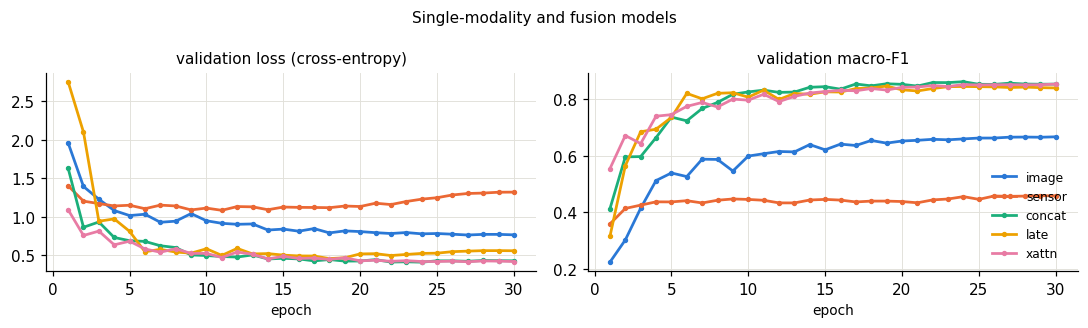

In [14]:
MODES = ['image', 'sensor', 'concat', 'late', 'xattn']
for mode in MODES:
    fit(f'base_{mode}', mode, tr_idx, va_idx)

tab_fusion = table([f'base_{m}' for m in MODES], MODES)
display(tab_fusion)
BEST_FUSION = tab_fusion.loc[['concat', 'late', 'xattn'], 'f1_mix'].idxmax()
BASE = f'base_{BEST_FUSION}'
print('best fusion by f1_mix:', BEST_FUSION)
plot_curves([f'base_{m}' for m in MODES], MODES, 'Single-modality and fusion models')

**Which class needs which modality?** Rincian skor F1 per kelas membedah spesialisasi masing-masing sensor:
- **Kelas dominan citra (gores, noda, kontaminasi):** Skor image tinggi sementara sensor mendekati nol, selaras dengan temuan eksplorasi bahwa cacat permukaan ringan tidak memengaruhi dinamika mesin press.
- **Kelas dominan sensor (las_dingin):** Tidak terlihat pada citra kamera, namun terdeteksi akurat oleh sensor melalui penurunan level arus listrik.
- **Kelas sinergis (retak, gelembung, normal):** Menggabungkan kedua modalitas memberikan lonjakan F1 yang konsisten melampaui model single-modality terbaik.

,image,sensor,sensor (recorded),concat,late,xattn,fusion - image,fusion - sensor
normal,0.842,0.651,0.653,0.906,0.902,0.917,0.065,0.253
gores,0.734,0.114,0.117,0.771,0.766,0.789,0.038,0.654
noda,0.866,0.090,0.094,0.880,0.852,0.875,0.015,0.787
retak,0.613,0.622,0.640,0.719,0.697,0.678,0.107,0.080
gelembung,0.657,0.737,0.760,0.806,0.781,0.822,0.149,0.046
las_dingin,0.000,0.913,0.938,0.927,0.919,0.927,0.927,-0.011
kontaminasi,0.956,0.080,0.081,0.959,0.959,0.962,0.003,0.878


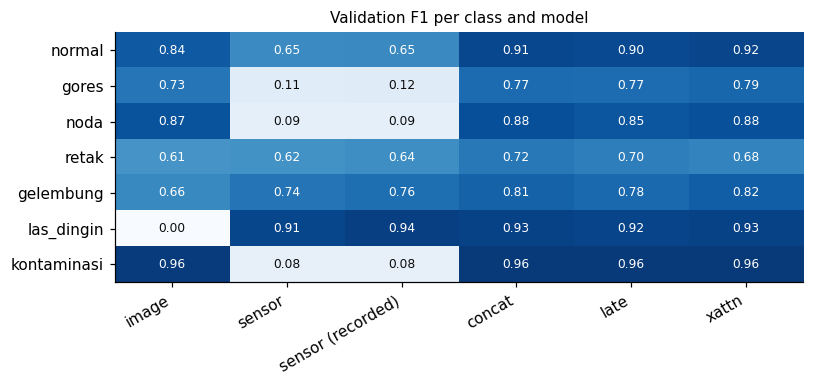

In [15]:
va_has = has_tr[va_idx]
pc = pd.DataFrame({m: per_class_f1(RUNS[f'base_{m}']['val_prob'], va_idx) for m in MODES}, index=CLASSES)
pc.insert(2, 'sensor (recorded)', per_class_f1(RUNS['base_sensor']['val_prob'][va_has], va_idx[va_has]))
pc['fusion - image'] = pc[BEST_FUSION] - pc['image']
pc['fusion - sensor'] = pc[BEST_FUSION] - pc['sensor (recorded)']
display(pc.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
heat(ax, pc.iloc[:, :6].values, CLASSES, list(pc.columns[:6]), 'Validation F1 per class and model')
plt.tight_layout(); plt.show()

## 6. Imperfect labels (d)

### 6.1 Looking for likely mislabels

Karena dataset latih diberi label oleh inspektur manusia, potensi kesalahan pelabelan label noise dianalisis menggunakan prediksi out-of-fold (OOF) dimana data latih dibagi menjadi 3 fold terstratifikasi sehingga setiap unit memperoleh distribusi probabilitas dari model yang tidak pernah melihat label unit tersebut selama pelatihan.

In [16]:
oof = np.zeros((N, K), np.float32)
skf = StratifiedKFold(CFG['oof_folds'], shuffle=True, random_state=0)
for k, (a, b) in enumerate(skf.split(np.zeros(N), y_all)):
    R = fit(f'oof{k}_{BEST_FUSION}', BEST_FUSION, a, b, epochs=CFG['oof_epochs'], verbose=False)
    oof[b] = R['val_prob']
print('out-of-fold macro-F1:', round(macro_f1(y_all, oof.argmax(1)), 4))

thr = np.array([oof[y_all == k, k].mean() for k in range(K)])           # ambang kepercayaan per kelas
conf = oof >= thr
cl = np.where(conf, oof, -1).argmax(1)                                   # kelas paling meyakinkan di atas ambang
flag = conf.any(1) & (cl != y_all)
print(f'flagged as likely mislabelled: {flag.sum():,} of {N:,} ({flag.mean():.1%})')
print('flagged share by line:', pd.Series(flag).groupby(meta_tr['lini'].values).mean().round(3).to_dict(),
      '| with sensor:', round(flag[has_tr].mean(), 3), '| without sensor:', round(flag[~has_tr].mean(), 3) if (~has_tr).any() else 'n/a')

[oof0_concat] loaded from disk | val macro-F1 0.7802
[oof1_concat] loaded from disk | val macro-F1 0.7882
[oof2_concat] loaded from disk | val macro-F1 0.7854
out-of-fold macro-F1: 0.7846
flagged as likely mislabelled: 3,472 of 48,000 (7.2%)
flagged share by line: {'A': 0.08, 'B': 0.048} | with sensor: 0.074 | without sensor: 0.038


Heatmap di bawah memetakan proporsi sampel berlabel asli (baris) yang diprediksi secara meyakinkan ke tiap kelas oleh model OOF (kolom) elemen di luar diagonal utama menyoroti pasangan kelas yang paling sering tertukar oleh inspektur. Di bawahnya ditampilkan 16 unit dengan margin ketidaksepakatan tertinggi (label diberikan → saran model), dengan catatan bahwa perbedaan yang melibatkan las_dingin bersumber dari anomali sinyal sensor.

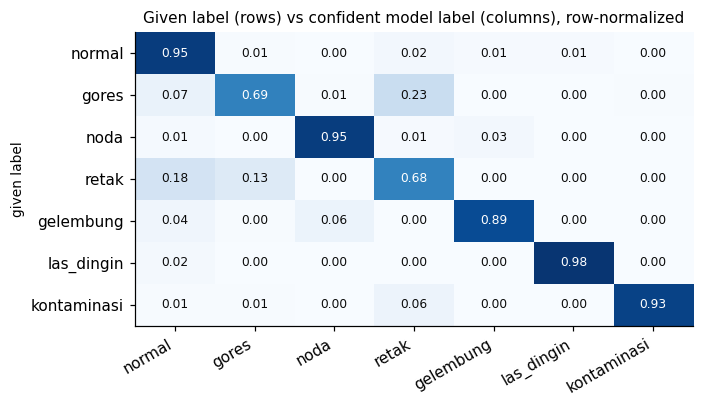

,normal,gores,noda,retak,gelembung,las_dingin,kontaminasi
flagged share of the class,0.031,0.225,0.043,0.209,0.085,0.02,0.057


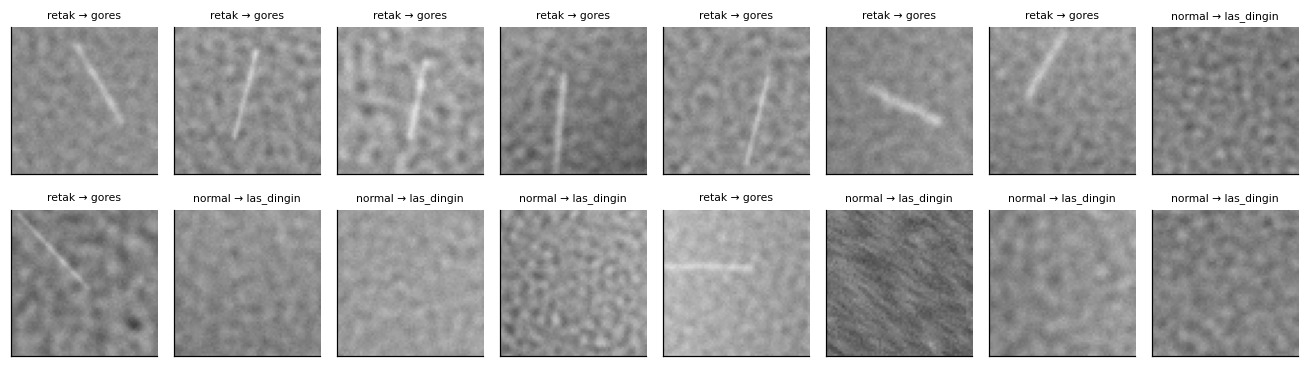

In [17]:
J = confusion_matrix(y_all[conf.any(1)], cl[conf.any(1)], labels=np.arange(K)).astype(float)
J = J / np.maximum(J.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
heat(ax, J, CLASSES, CLASSES, 'Given label (rows) vs confident model label (columns), row-normalized')
ax.set_ylabel('given label'); plt.tight_layout(); plt.show()

flag_rate = pd.Series(flag).groupby(y_all).mean().reindex(range(K)).fillna(0)
flag_rate.index = CLASSES
display(flag_rate.round(3).to_frame('flagged share of the class').T)

margin = np.where(flag, oof[np.arange(N), cl] - oof[np.arange(N), y_all], -1)
top = np.argsort(-margin)[:16]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for ax, i in zip(axes.ravel(), top):
    ax.imshow(img_tr[i], cmap='gray', vmin=0, vmax=255); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f'{CLASSES[y_all[i]]} → {CLASSES[cl[i]]}' if flag[i] else '-', fontsize=7)
plt.tight_layout(); plt.show()

### 6.2 A noise-robust loss

Untuk meredam dampak gradien keliru akibat label yang salah, dua metode regularisasi loss diuji dengan mempertahankan arsitektur dan hyperparameter lainnya:
- ce: standar sebagai pembanding dasar.
- ls: melunakkan vektor target menjadi 0.9 untuk kelas yang diberikan dan membagi 0.1 ke kelas lain sehingga model tidak dipaksa menjadi overconfident pada label yang berpotensi keliru.
- gce: otomatis mengecilkan bobot gradien pada sampel yang sangat bertentangan dengan keyakinan model.

Karena himpunan validasi berasal dari sumber inspektur yang sama, label validasi juga mengandung tingkat noise serupa. Selisih kecil antar metode perlu dibandingkan dengan variasi antar seed

In [18]:
fit(f'noise_ls_{BEST_FUSION}',  BEST_FUSION, tr_idx, va_idx, loss='ls')
fit(f'noise_gce_{BEST_FUSION}', BEST_FUSION, tr_idx, va_idx, loss='gce')
tab_noise = table([BASE, f'noise_ls_{BEST_FUSION}', f'noise_gce_{BEST_FUSION}'], ['ce', 'ls', 'gce'])
display(tab_noise)
BEST_LOSS = tab_noise['f1_mix'].idxmax()
print('best loss by f1_mix:', BEST_LOSS)

[noise_ls_concat] loaded from disk | val macro-F1 0.8571
[noise_gce_concat] loaded from disk | val macro-F1 0.8595


,f1,f1_A,f1_B,f1_mix,acc,minutes
run,,,,,,
ce,0.8528,0.8846,0.7543,0.8075,0.8719,3.7039
ls,0.8571,0.8922,0.7490,0.8073,0.8757,3.7194
gce,0.8595,0.8921,0.7569,0.8127,0.8782,3.7849


best loss by f1_mix: gce


## 7. Domain shift between production lines (e)

### 7.1 Performance per line

Evaluasi terpisah pada unit validasi lini A dan lini B memperlihatkan dampak dari ketimpangan jumlah sampel latih (lini B tiga kali lebih sedikit) serta perbedaan karakteristik sensor dan latar citra. Kesenjangan ini krusial karena lini B menyumbang porsi mayoritas pada data uji.

,f1,f1_A,f1_B,f1_mix
run,,,,
base (concat),0.8528,0.8846,0.7543,0.8075


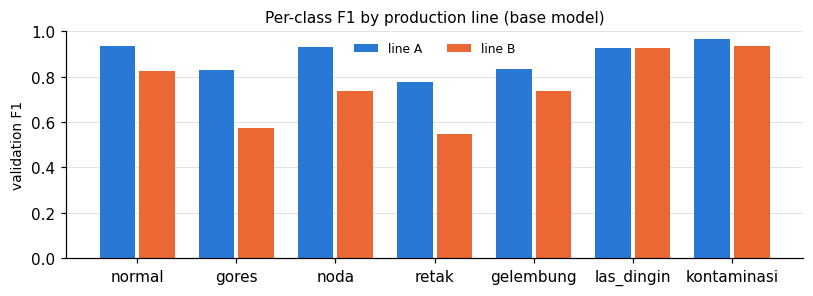

In [19]:
p = RUNS[BASE]['val_prob']; la = line_all[va_idx]
display(table([BASE], [f'base ({BEST_FUSION})'])[['f1', 'f1_A', 'f1_B', 'f1_mix']])
f1_line = pd.DataFrame({'line A': per_class_f1(p[la == 0], va_idx[la == 0]),
                        'line B': per_class_f1(p[la == 1], va_idx[la == 1])}, index=CLASSES)
fig, ax = plt.subplots(figsize=(7.5, 2.8)); x = np.arange(K)
ax.bar(x - 0.2, f1_line['line A'], 0.36, label='line A', color=PAL[0])
ax.bar(x + 0.2, f1_line['line B'], 0.36, label='line B', color=PAL[1])
ax.set_xticks(x); ax.set_xticklabels(CLASSES); ax.set_ylabel('validation F1'); ax.set_ylim(0, 1); ax.grid(axis='x', visible=False)
ax.set_title('Per-class F1 by production line (base model)'); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

### 7.2 Two ways to handle it

Dua pendekatan diuji untuk menjembatani perbedaan distribusi antara lini A dan lini B:
- **Normalisasi Per Lini:** Menstandardisasi citra dan sensor menggunakan statistik mean dan std dari masing-masing lini secara terpisah. Langkah ini menghilangkan pergeseran kecerahan citra maupun selisih suhu pada lini B sehingga masukan jaringan berada pada skala yang seragam.
- **Normalisasi Per Lini + Pembobotan Lini:** Selain menormalisasi statistik per lini, setiap sampel latih diboboti sebesar P_test(lini) / P_train(lini) (0.53 untuk lini A dan 2.40 untuk lini B). Teknik importance weighting standar untuk covariate shift ini menyeimbangkan kontribusi gradien selama optimasi agar sesuai dengan komposisi lini pada data uji.

Kedua teknik hanya memanfaatkan atribut metadata lini yang tersedia untuk seluruh data uji tanpa menyentuh label uji.

In [20]:
fit(f'dom_line_{BEST_FUSION}',  BEST_FUSION, tr_idx, va_idx, norm='line')
fit(f'dom_linew_{BEST_FUSION}', BEST_FUSION, tr_idx, va_idx, norm='line', line_w=True)
DOM = {'global norm': dict(norm='global', line_w=False), 'per-line norm': dict(norm='line', line_w=False),
       'per-line norm + line weights': dict(norm='line', line_w=True)}
tab_dom = table([BASE, f'dom_line_{BEST_FUSION}', f'dom_linew_{BEST_FUSION}'], list(DOM))
display(tab_dom)
BEST_DOM = tab_dom['f1_mix'].idxmax()
print('best domain handling by f1_mix:', BEST_DOM)

[dom_line_concat] loaded from disk | val macro-F1 0.8430
[dom_linew_concat] loaded from disk | val macro-F1 0.8317


,f1,f1_A,f1_B,f1_mix,acc,minutes
run,,,,,,
global norm,0.8528,0.8846,0.7543,0.8075,0.8719,3.7039
per-line norm,0.8430,0.8807,0.7271,0.7895,0.8650,3.7221
per-line norm + line weights,0.8317,0.8657,0.7285,0.7839,0.8562,3.7166


best domain handling by f1_mix: global norm


## 8. Missing sensor (f)

Keandalan arsitektur fusi ketika rekaman sensor absen ditopang oleh tiga komponen: kanal masker biner, vektor parameter terlatih, serta modality dropout selama pelatihan. Pengujian berikut mengevaluasi performa model pada berbagai skenario ketersediaan sensor:
- as recorded: Kondisi data validasi apa adanya.
- sensor complete / one channel missing / no sensor: Evaluasi pada subkelompok unit validasi sesuai kelengkapan rekaman alaminya.
- sensor forced off: Simulasi terburuk di mana seluruh channel sensor dimatikan secara paksa untuk semua unit validasi.

Sebagai pembanding, baris ketiga menunjukkan performa model fusi serupa yang dilatih tanpa modality dropout (p_sen=0, p_ch=0). Model yang dibiasakan dengan modality dropout diharapkan tetap bisa menjaga performanya mendekati model image only saat sensor mati total bukan anjlok drastis karena terlalu bergantung pada informasi sensor.

In [21]:
fit(f'nodrop_{BEST_FUSION}', BEST_FUSION, tr_idx, va_idx, p_sen=0.0, p_ch=0.0)

va_none = ~has_tr[va_idx]; va_full = complete_tr[va_idx]; va_part = ~va_none & ~va_full
def missing_row(name):
    R = RUNS[name]; p = R['val_prob']
    p_off = predict(load_model(R), TR, va_idx, R['norm'], sensor_off=True)
    f = lambda prob, m: macro_f1(y_all[va_idx][m], prob.argmax(1)[m])
    return {'as recorded': f(p, np.ones(len(va_idx), bool)), 'sensor complete': f(p, va_full),
            'one channel missing': f(p, va_part), 'no sensor': f(p, va_none),
            'sensor forced off': f(p_off, np.ones(len(va_idx), bool))}
tab_missing = pd.DataFrame({'image only': missing_row('base_image'),
                            f'{BEST_FUSION} + modality dropout': missing_row(BASE),
                            f'{BEST_FUSION}, no modality dropout': missing_row(f'nodrop_{BEST_FUSION}')}).T
print('validation units | complete:', int(va_full.sum()), '| one channel missing:', int(va_part.sum()), '| no sensor:', int(va_none.sum()))
display(tab_missing.round(4))

[nodrop_concat] loaded from disk | val macro-F1 0.8292
validation units | complete: 6625 | one channel missing: 231 | no sensor: 344


,as recorded,sensor complete,one channel missing,no sensor,sensor forced off
image only,0.6666,0.6665,0.6781,0.6627,0.6666
concat + modality dropout,0.8528,0.8602,0.8264,0.6667,0.6500
"concat, no modality dropout",0.8292,0.8387,0.7368,0.6450,0.6133


## 9. Final model (g)

Konfigurasi FINAL merangkum kombinasi komponen terbaik dari eksperimen Bagian 5 hingga 7. Model final ini kemudian dilatih ulang menggunakan tiga random seed berbeda (0, 1, 2) untuk mengukur stabilitas pelatihan sekaligus mendapatkan rata-rata dan simpangan baku performa.

In [22]:
FINAL = dict(mode=BEST_FUSION, loss=BEST_LOSS, **DOM[BEST_DOM])
print('final recipe:', FINAL)
FINAL_NAMES = [f'final_s{s}' for s in CFG['seeds']]
for s, n in zip(CFG['seeds'], FINAL_NAMES):
    fit(n, FINAL['mode'], tr_idx, va_idx, seed=s, loss=FINAL['loss'], norm=FINAL['norm'], line_w=FINAL['line_w'])

tab_final = table(FINAL_NAMES)
display(tab_final)
display(tab_final.drop(columns='minutes').agg(['mean', 'std']).round(4))

final recipe: {'mode': 'concat', 'loss': 'gce', 'norm': 'global', 'line_w': False}
[final_s0] loaded from disk | val macro-F1 0.8595
[final_s1] loaded from disk | val macro-F1 0.8523
[final_s2] loaded from disk | val macro-F1 0.8594


,f1,f1_A,f1_B,f1_mix,acc,minutes
run,,,,,,
final_s0,0.8595,0.8921,0.7569,0.8127,0.8782,3.7055
final_s1,0.8523,0.8851,0.7476,0.8048,0.8728,3.7399
final_s2,0.8594,0.8945,0.7493,0.8091,0.8778,3.7153


,f1,f1_A,f1_B,f1_mix,acc
mean,0.8571,0.8906,0.7513,0.8089,0.8763
std,0.0041,0.0049,0.0050,0.0040,0.0030


**Learning curves.** Grafik memvisualisasikan dinamika cross-entropy loss dan macro-F1 pada fase latih (biru) dan validasi (oren) di seluruh epoch untuk ketiga seed. Konsistensi lintasan ketiga kurva menunjukkan konvergensi yang stabil tanpa gejala overfitting.

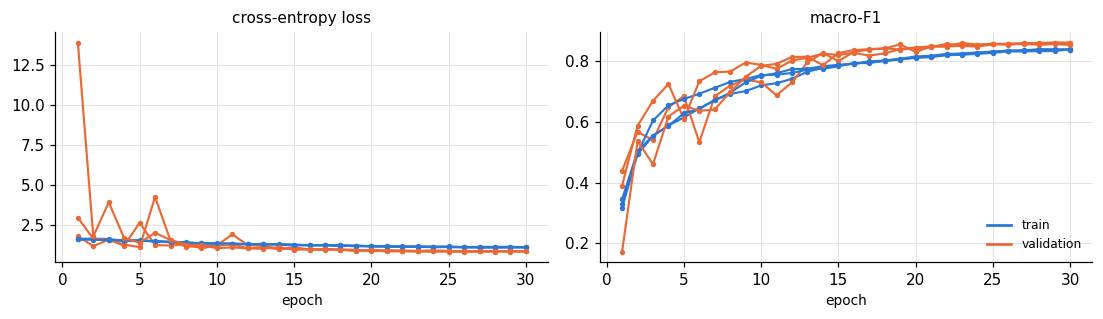

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for n in FINAL_NAMES:
    h = pd.DataFrame(RUNS[n]['hist'])
    for ax, a, b in [(axes[0], 'train_loss', 'val_loss'), (axes[1], 'train_f1', 'val_f1')]:
        ax.plot(h['epoch'], h[a], color=PAL[0], lw=1.4, marker='o', ms=2.5); ax.plot(h['epoch'], h[b], color=PAL[1], lw=1.4, marker='o', ms=2.5)
axes[0].set_title('cross-entropy loss'); axes[1].set_title('macro-F1')
for ax in axes: ax.set_xlabel('epoch')
axes[1].legend(handles=[mpl.lines.Line2D([], [], color=PAL[0], label='train'), mpl.lines.Line2D([], [], color=PAL[1], label='validation')])
plt.tight_layout(); plt.show()

**Ensemble and error analysis.** Untuk meningkatkan generalisasi prediksi akhir, probabilitas keluaran dari ketiga model seed dirata-ratakan dengan tambahan TTA berupa 4 kombinasi flip citra. Laporan klasifikasi dan confusion matrix ternormalisasi baris di bawah memetakan presisi, recall, serta pola kesalahan antar kelas pada himpunan validasi.

ensemble of 3 seeds + flip TTA on validation: {'f1': 0.8663, 'f1_A': 0.8971, 'f1_B': 0.7684, 'f1_mix': 0.8218, 'acc': 0.8842}
              precision    recall  f1-score   support

      normal      0.884     0.947     0.914      3583
       gores      0.851     0.745     0.795       844
        noda      0.909     0.856     0.882       716
       retak      0.805     0.725     0.763       541
   gelembung      0.828     0.812     0.820       515
  las_dingin      0.960     0.900     0.929       648
 kontaminasi      0.966     0.958     0.962       353

    accuracy                          0.884      7200
   macro avg      0.886     0.849     0.866      7200
weighted avg      0.884     0.884     0.883      7200



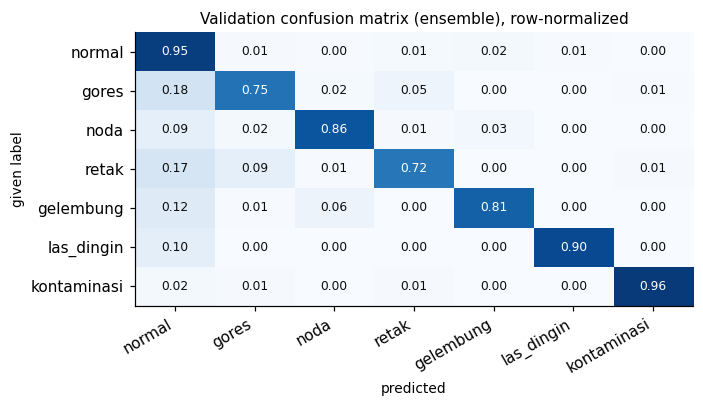

In [24]:
finals = [RUNS[n] for n in FINAL_NAMES]
p_ens = np.mean([predict(load_model(R), TR, va_idx, R['norm'], tta=True) for R in finals], 0)
s_ens = score(p_ens, va_idx)
print('ensemble of 3 seeds + flip TTA on validation:', {k: round(v, 4) for k, v in s_ens.items()})

yv, pv = y_all[va_idx], p_ens.argmax(1)
print(classification_report(yv, pv, labels=np.arange(K), target_names=CLASSES, digits=3, zero_division=0))
cm = confusion_matrix(yv, pv, labels=np.arange(K)).astype(float); cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
heat(ax, cm, CLASSES, CLASSES, 'Validation confusion matrix (ensemble), row-normalized')
ax.set_ylabel('given label'); ax.set_xlabel('predicted'); plt.tight_layout(); plt.show()

**Test predictions.** Kombinasi model 3-seed dan TTA yang sama dijalankan pada data uji untuk menyimpan hasil akhir ke prediksi_klasifikasi.csv (format id_unit, kelas). Sebagai pengecekan akhir, rasio hasil prediksi pada lini A dan lini B dibandingkan dengan komposisi kelas pada data latih guna memastikan model tidak condong secara ekstrem ke salah satu kelas saja.

In [25]:
p_te = np.mean([predict(load_model(R), TE, np.arange(len(meta_te)), R['norm'], tta=True) for R in finals], 0)
sub = pd.DataFrame({'id_unit': meta_te['id_unit'].values, 'kelas': [CLASSES[i] for i in p_te.argmax(1)]})
assert len(sub) == len(meta_te) and sub['id_unit'].is_unique and set(sub['kelas']) <= set(CLASSES)
sub.to_csv(OUT_DIR / 'prediksi_klasifikasi.csv', index=False)
sub.to_csv('prediksi_klasifikasi.csv', index=False)
np.save(OUT_DIR / 'prob_test.npy', p_te)
print('saved', OUT_DIR / 'prediksi_klasifikasi.csv', '|', len(sub), 'rows')
display(sub.head())

share = pd.DataFrame({'train labels': pd.Series(y_all).value_counts(normalize=True),
                      'test pred, line A': pd.Series(p_te.argmax(1)[line_te == 0]).value_counts(normalize=True),
                      'test pred, line B': pd.Series(p_te.argmax(1)[line_te == 1]).value_counts(normalize=True)}).reindex(range(K)).fillna(0)
share.index = CLASSES
display(share.round(3))

saved /content/drive/MyDrive/UTS_DL/hasil_tugas1/prediksi_klasifikasi.csv | 16000 rows


,id_unit,kelas
0,U412019,gores
1,U929275,retak
2,U845264,normal
3,U382231,normal
4,U156089,gores


,train labels,"test pred, line A","test pred, line B"
normal,0.498,0.523,0.579
gores,0.117,0.112,0.081
noda,0.099,0.097,0.084
retak,0.075,0.065,0.061
gelembung,0.071,0.072,0.065
las_dingin,0.090,0.081,0.085
kontaminasi,0.049,0.050,0.045


## 10. Summary and reproduction

Seluruh pelatihan dijadikan satu dalam file ringkasan_run.csv sebagai rujukan dokumentasi. Baris kode terakhir memuat ulang bobot tersimpan dari final_s0 dan menghitung ulang skor validasinya untuk memastikan hasil eksperimen dapat direproduksi secara identik.

In [26]:
summary = table(list(RUNS))
summary.insert(0, 'config', [f"{R['mode']} | {R['loss']} | {R['norm']}{' +w' if R['line_w'] else ''} | seed {R['seed']} | {R['epochs']} ep"
                             for R in RUNS.values()])
summary.to_csv(OUT_DIR / 'ringkasan_run.csv')
display(summary)

R = RUNS['final_s0']
again = predict(load_model(R), TR, R['va'], R['norm'])
print(f"final_s0 val macro-F1 | stored {score(R['val_prob'], R['va'])['f1']:.4f} | recomputed from weights {score(again, R['va'])['f1']:.4f}")

,config,f1,f1_A,f1_B,f1_mix,acc,minutes
run,,,,,,,
base_image,image | ce | global | seed 0 | 30 ep,0.6666,0.7076,0.5360,0.6074,0.7722,3.0187
base_sensor,sensor | ce | global | seed 0 | 30 ep,0.4579,0.4762,0.4019,0.4321,0.5540,0.8221
base_concat,concat | ce | global | seed 0 | 30 ep,0.8528,0.8846,0.7543,0.8075,0.8719,3.7039
base_late,late | ce | global | seed 0 | 30 ep,0.8392,0.8769,0.7214,0.7853,0.8631,3.7019
base_xattn,xattn | ce | global | seed 0 | 30 ep,0.8528,0.8874,0.7447,0.8034,0.8775,4.5030
oof0_concat,concat | ce | global | seed 0 | 12 ep,0.7802,0.8204,0.6475,0.7212,0.8261,1.2744
oof1_concat,concat | ce | global | seed 0 | 12 ep,0.7882,0.8267,0.6538,0.7298,0.8300,1.2768
oof2_concat,concat | ce | global | seed 0 | 12 ep,0.7854,0.8266,0.6426,0.7229,0.8298,1.2771
noise_ls_concat,concat | ls | global | seed 0 | 30 ep,0.8571,0.8922,0.7490,0.8073,0.8757,3.7194


final_s0 val macro-F1 | stored 0.8595 | recomputed from weights 0.8595
